# Multiple Linear regression

In [35]:
# Importing necessary Libraries 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Loading the dataset 

In [36]:
# Reading the data 
data = pd.read_csv("YachtHydrodynamics.csv")

In [37]:
# Displaying first few lines
display(data.head())

,"Longitudinal position of the center of buoyancy, adimensional",Prismatic coefficient,Length-displacement ratio,Beam-draught ratio,Length-beam ratio,Froude number,Residuary resistance per unit weight of displacement
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


## Splitting od data into features and targets

In [38]:
y = data.iloc[:, 0].values #first column as target
x = data.iloc[:, 1:].values #Second column as feature 

## Add intercept term (bias) - column of ones

In [39]:
print("Shape of X:",x.shape)
print("Shape of Y:", y.shape)

Shape of X: (308, 6)
Shape of Y: (308,)


## Train-Test Split (80%-20%)

In [40]:
np.random.seed(42)
rows = x.shape[0]
rp = np.random.permutation(rows)

train_size = int(np.round(rows*0.8))
train_idx, test_idx = rp[:train_size], rp[train_size:]

x_train, x_test = x[train_idx], x[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training sample:",x_train.shape[0])
print("Testing sample:",x_test.shape[0])

Training sample: 246
Testing sample: 62


## Add the intercept term (bias) - column of ones 

In [41]:
x_train = np.column_stack((np.ones(x_train.shape[0]), x_train))
x_test = np.column_stack((np.ones(x_test.shape[0]), x_test))
print("Shape of x_train with intercept: ", x_train.shape)
print("Shape of x_test with intercept: ", x_test.shape)

Shape of x_train with intercept:  (246, 7)
Shape of x_test with intercept:  (62, 7)


## Regression Coefficient 

In [42]:
XtX = np.dot(x_train.T, x_train)
XtX_inv = np.linalg.inv(XtX)
XtX_inv_Xt = np.dot(XtX_inv, x_train.T)
beta = np.dot(XtX_inv_Xt, y_train)
print("Regression Coefficient beta: \n",beta)

Regression Coefficient beta: 
 [ 2.77258477e-01 -3.68114951e+00 -1.20140370e+00  4.57901626e-01
  1.10171224e+00 -7.20828137e-01  2.76487696e-03]


## Predicting the target values

In [43]:
y_pred = np.dot(x_test, beta) 

print("Actual values: ", y_test[:10])
print("Predicted values: ", y_pred[:10])

Actual values:  [-5.  -2.3 -2.3 -2.3 -2.3 -5.   0.  -2.3 -2.3  0. ]
Predicted values:  [-2.37094483 -2.36800805 -2.24776472 -2.40307333 -2.44264186 -2.40402782
 -2.40439175 -2.38981221 -2.40158871 -2.46446002]


## Evaluate Model Performance (RMSE)

In [44]:
rss = np.sum((y_test - y_pred) ** 2)
rmse = np.sqrt(rss / len(y_test))

print(f"Root Mean Square Error (RMSE): {rmse:.4f}")

ss_total = np.sum((y_test - np.mean(y_test))**2)
r2 = 1- (rss / ss_total) if ss_total != 0 else float("nan")
print(f"R-Square: {r2:.4f}")

Root Mean Square Error (RMSE): 1.4583
R-Square: -0.0059


## Visualization of actual vs Predicted 

<ipython-input-45-a6e7f71106b4>:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


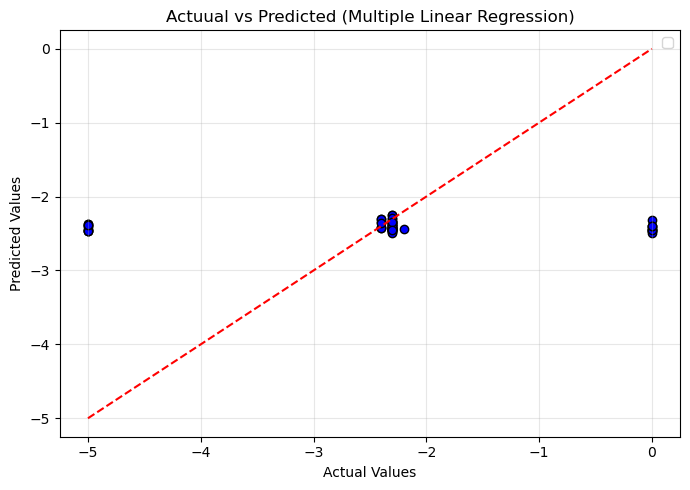

In [45]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, color='blue', edgecolor='black')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actuual vs Predicted (Multiple Linear Regression)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Display Actual vs Predicted Values

In [46]:
comparison = pd.DataFrame({'Actual Values': y_test,'Predicted Values': y_pred})
print(comparison.head(10))

   Actual Values  Predicted Values
0           -5.0         -2.370945
1           -2.3         -2.368008
2           -2.3         -2.247765
3           -2.3         -2.403073
4           -2.3         -2.442642
5           -5.0         -2.404028
6            0.0         -2.404392
7           -2.3         -2.389812
8           -2.3         -2.401589
9            0.0         -2.464460


## Prediction for a New Data Point

In [47]:
new_data = x_test[0:1]
new_prediction = new_data @ beta

print("Predicted Value:", new_prediction[0])
print("Actual Value:", y_test[0])

Predicted Value: -2.370944832801615
Actual Value: -5.0


## Visualization of Residuals

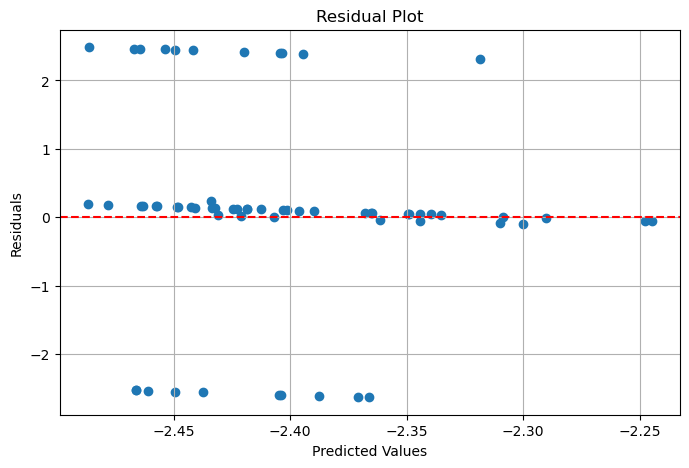

In [48]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()